## Instalasi (jalankan sekali)
VS Code: pilih kernel dari environment Python 3.11, kemudian jalankan sel ini. Setelah instalasi, *restart kernel* apabila diperlukan.

In [5]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [6]:
# Pengaturan proyek. Jika sudah ada folder Kaggle di Mac, isi SOURCE_FOLDER.
from pathlib import Path
import os, re, csv, json, shutil, hashlib, zipfile, warnings
from collections import Counter, defaultdict
from PIL import Image, UnidentifiedImageError
import pandas as pd

DATASET_SLUG = 'cyanex1702/oceanic-life-dataset'
PROJECT_DIR = Path.cwd().resolve()
# Contoh: SOURCE_FOLDER = Path('/Users/mochammadmarillivio/Downloads/Oceanic_Life-Dataset')
SOURCE_FOLDER = None   # Biarkan None agar dicari/diunduh otomatis
OUT_PARENT = PROJECT_DIR / 'hasil_pengelompokan'
FINAL_ROOT = OUT_PARENT / 'Oceanic_Life-Dataset'
PROPOSAL_ROOT = OUT_PARENT / 'Usulan_AI' / 'Oceanic_Life-Dataset'
UNLABELED_ROOT = OUT_PARENT / 'Belum_Berlabel'
REVIEW_CSV = OUT_PARENT / 'review_labels.csv'

CLASSES = ['Fish','Coral','Shark','Octopuses','Crustaceans','Seaweed','Sponges','Other marine organisms']
IMG_EXTS = {'.jpg','.jpeg','.png','.bmp','.webp','.tif','.tiff'}
GENERIC = {'dataset','oceanic life dataset','oceanic life','oceanic life dataset 1','images',
           'image','imgs','img','photos','pictures','all','raw','data','original',
           'train','training','valid','validation','val','test','testing','output',
           'archives','archive','samples','export','results','segmented','annotations',
           'labels','images train','images test'}
ALIAS = {
    'fish':'Fish', 'fishes':'Fish',
    'coral':'Coral','corals':'Coral','coral reef':'Coral',
    'shark':'Shark','sharks':'Shark',
    'octopus':'Octopuses','octopuses':'Octopuses','octopi':'Octopuses',
    'crustaceans':'Crustaceans','crustacean':'Crustaceans',
    'crab':'Crustaceans','crabs':'Crustaceans', 'lobster':'Crustaceans','lobsters':'Crustaceans',
    'shrimp':'Crustaceans','shrimps':'Crustaceans', 'prawn':'Crustaceans','prawns':'Crustaceans',
    'seaweed':'Seaweed','seaweeds':'Seaweed','kelp':'Seaweed','algae':'Seaweed',
    'sponge':'Sponges','sponges':'Sponges','sea sponge':'Sponges',
    'other marine organisms':'Other marine organisms',
    'other marine organism':'Other marine organisms','other marine objects':'Other marine organisms',
    'jellyfish':'Other marine organisms','starfish':'Other marine organisms',
    'sea turtle':'Other marine organisms','seahorse':'Other marine organisms',
    'sea anemone':'Other marine organisms'
}

def normalized(text):
    return ' '.join(re.findall(r'[a-z0-9]+', str(text).lower()))

def exact_category(text):
    return ALIAS.get(normalized(text))

def discover_images(root):
    root = Path(root)
    ignored = {'__macosx','.git','.ipynb_checkpoints','hasil_pengelompokan',
               'usulan_ai','belum_berlabel','output','.venv','venv'}
    result=[]
    for parent,dirs,files in os.walk(root):
        dirs[:] = [d for d in dirs if d.lower() not in ignored and not d.startswith('.')]
        for name in files:
            p=Path(parent)/name
            if p.suffix.lower() in IMG_EXTS and not name.startswith('.'):
                result.append(p)
    return sorted(result, key=lambda p:str(p).casefold())

def choose_source():
    if SOURCE_FOLDER is not None:
        p=Path(SOURCE_FOLDER).expanduser().resolve()
        if not p.is_dir(): raise FileNotFoundError(f'Folder tidak ditemukan: {p}')
        if not discover_images(p): raise FileNotFoundError(f'Folder belum berisi gambar: {p}')
        return p
    home=Path.home()
    candidates=[PROJECT_DIR/'Oceanic_Life-Dataset', PROJECT_DIR/'oceanic-life-dataset',
                PROJECT_DIR/'dataset', home/'Downloads'/'Oceanic_Life-Dataset',
                home/'Downloads'/'Oceanic_Life-Dataset'/'Oceanic_Life-Dataset',
                home/'Downloads'/'Praktikum_CNN_Oceanic_Life'/'dataset',
                home/'Downloads'/'Oceanic_Life_CNN'/'dataset']
    for p in candidates:
        if p.is_dir() and discover_images(p):
            print('Folder lokal ditemukan:',p)
            return p.resolve()
    print('Belum ada folder Oceanic Life lokal. Mengunduh dari Kaggle ...')
    import kagglehub
    p=Path(kagglehub.dataset_download(DATASET_SLUG)).resolve()
    if p.is_dir() and discover_images(p): return p
    zips=list(p.rglob('*.zip')) if p.is_dir() else ([p] if p.suffix.lower()=='.zip' else [])
    if zips:
        target=PROJECT_DIR/'dataset_ekstrak_oceanic'
        target.mkdir(exist_ok=True)
        for zpath in zips:
            with zipfile.ZipFile(zpath) as zf:
                for entry in zf.infolist():
                    dest=(target/entry.filename).resolve()
                    if not dest.is_relative_to(target.resolve()):
                        raise RuntimeError('Arsip ZIP mengandung path tidak aman.')
                zf.extractall(target)
        if discover_images(target): return target
    raise FileNotFoundError('Unduhan tidak berisi gambar yang terbaca. Periksa Kaggle atau SOURCE_FOLDER.')

DATA_DIR=choose_source()
PATHS=discover_images(DATA_DIR)
print('\nSUMBER DATASET:', DATA_DIR)
print('TOTAL GAMBAR TERDETEKSI:', len(PATHS))
print('12 CONTOH PATH:')
for p in PATHS[:12]: print(' •',p.relative_to(DATA_DIR))
print('FOLDER GAMBAR TERBANYAK:')
for dirname,n in Counter(str(p.parent.relative_to(DATA_DIR)) for p in PATHS).most_common(10):
    print(f' • {dirname}: {n}')
print('File CSV:',[str(p.relative_to(DATA_DIR)) for p in list(DATA_DIR.rglob('*.csv'))[:10]])

Belum ada folder Oceanic Life lokal. Mengunduh dari Kaggle ...

SUMBER DATASET: /Users/mochammadmarillivio/.cache/kagglehub/datasets/cyanex1702/oceanic-life-dataset/versions/1
TOTAL GAMBAR TERDETEKSI: 7960
12 CONTOH PATH:
 • OceanicLife Dataset/001v5h0d.jpg
 • OceanicLife Dataset/002ojjl6.jpg
 • OceanicLife Dataset/00dx9zud.JPG
 • OceanicLife Dataset/00gohyw5.jpg
 • OceanicLife Dataset/015e0ase.jpg
 • OceanicLife Dataset/015us06k.jpg
 • OceanicLife Dataset/017s6334.jpeg
 • OceanicLife Dataset/01cqbman.jpg
 • OceanicLife Dataset/01fifu6i.jpg
 • OceanicLife Dataset/01ji8io2.jpg
 • OceanicLife Dataset/01ly8g4q.jpg
 • OceanicLife Dataset/01n1y044.jpg
FOLDER GAMBAR TERBANYAK:
 • OceanicLife Dataset: 7960
File CSV: []


In [9]:
from pathlib import Path

# Menggunakan 7.952 gambar yang sudah dikelompokkan AI
DATA_DIR = (
    Path.home()
    / "Downloads"
    / "Oceanic_Life_CNN_PERBAIKAN_FOLDER"
    / "hasil_pengelompokan"
    / "Usulan_AI"
    / "Oceanic_Life-Dataset"
)

OUT_DIR = Path.cwd() / "output"
OUT_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = 128

# Periksa keberadaan folder
print("Lokasi dataset:", DATA_DIR)
print("Folder ditemukan:", DATA_DIR.is_dir())

kelas = [
    "Fish", "Coral", "Shark", "Octopuses",
    "Crustaceans", "Seaweed", "Sponges",
    "Other marine organisms"
]

ekstensi = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"}

total = 0
for nama_kelas in kelas:
    folder = DATA_DIR / nama_kelas
    jumlah = sum(
        1 for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in ekstensi
    ) if folder.is_dir() else 0

    print(f"{nama_kelas}: {jumlah} gambar")
    total += jumlah

print("\nTotal gambar:", total)

if total == 0:
    raise FileNotFoundError(
        "Folder pengelompokan tidak ditemukan atau masih kosong."
    )

if sum(
    (DATA_DIR / k).is_dir()
    for k in kelas
) < 2:
    raise ValueError("Minimal dua folder kelas diperlukan.")

Lokasi dataset: /Users/mochammadmarillivio/Downloads/Oceanic_Life_CNN_PERBAIKAN_FOLDER/hasil_pengelompokan/Usulan_AI/Oceanic_Life-Dataset
Folder ditemukan: True
Fish: 2596 gambar
Coral: 759 gambar
Shark: 1013 gambar
Octopuses: 377 gambar
Crustaceans: 760 gambar
Seaweed: 882 gambar
Sponges: 455 gambar
Other marine organisms: 1110 gambar

Total gambar: 7952


In [10]:
df, gambar_dilewati = scan_dataset(
    DATA_DIR, OUT_DIR, IMG_SIZE
)

print("Jumlah gambar valid:", len(df))
print("Jumlah kelas:", df["kelas"].nunique())
print("Gambar dilewati/duplikat:", len(gambar_dilewati))

display(
    df[
        [
            "kelas",
            "lebar_asli",
            "tinggi_asli",
            "mode_asli",
            "indikasi_kualitas"
        ]
    ].head(10)
)

/opt/miniconda3/envs/ds/lib/python3.11/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


  Memproses 2000/7952 gambar...
  Memproses 4500/7952 gambar...
  Memproses 6500/7952 gambar...
  Memproses 7500/7952 gambar...
Jumlah gambar valid: 1022
Jumlah kelas: 8
Gambar dilewati/duplikat: 6930


,kelas,lebar_asli,tinggi_asli,mode_asli,indikasi_kualitas
0,Coral,3000,4000,RGB,tidak_terindikasi
1,Coral,2400,2400,RGB,tidak_terindikasi
2,Coral,1117,1104,RGB,tidak_terindikasi
3,Coral,1600,1116,RGB,tidak_terindikasi
4,Coral,1024,683,RGB,tidak_terindikasi
5,Coral,852,480,RGB,tidak_terindikasi
6,Coral,750,490,RGB,tidak_terindikasi
7,Coral,1000,639,RGB,tidak_terindikasi
8,Coral,583,619,RGB,tidak_terindikasi
9,Coral,1156,650,RGB,tidak_terindikasi


## Langkah 2 — Eksplorasi Data / EDA
Menghitung jumlah per kelas, grafik distribusi, contoh citra, ukuran (piksel), format warna, indikasi kualitas, serta rasio ketimpangan kelas. Grafik dihasilkan dari data yang benar-benar ditemukan.

,Kelas,Jumlah gambar
0,Coral,92
1,Crustaceans,102
2,Fish,331
3,Octopuses,47
4,Other marine organisms,152
5,Seaweed,114
6,Shark,122
7,Sponges,62


Ukuran gambar - statistik:


,lebar_asli,tinggi_asli
count,1022.00,1022.00
mean,1226.78,894.08
std,854.07,634.05
min,32.00,32.00
25%,640.00,480.00
50%,1024.00,720.00
75%,1600.00,1067.00
max,6144.00,4378.00


Mode warna: {'RGB': 1011, 'RGBA': 6, 'P': 4, 'L': 1}
Rasio kelas terbesar/terkecil: 7.04
Analisis: Dataset tidak seimbang; class weight akan dipertimbangkan.

 Distribusi kelas


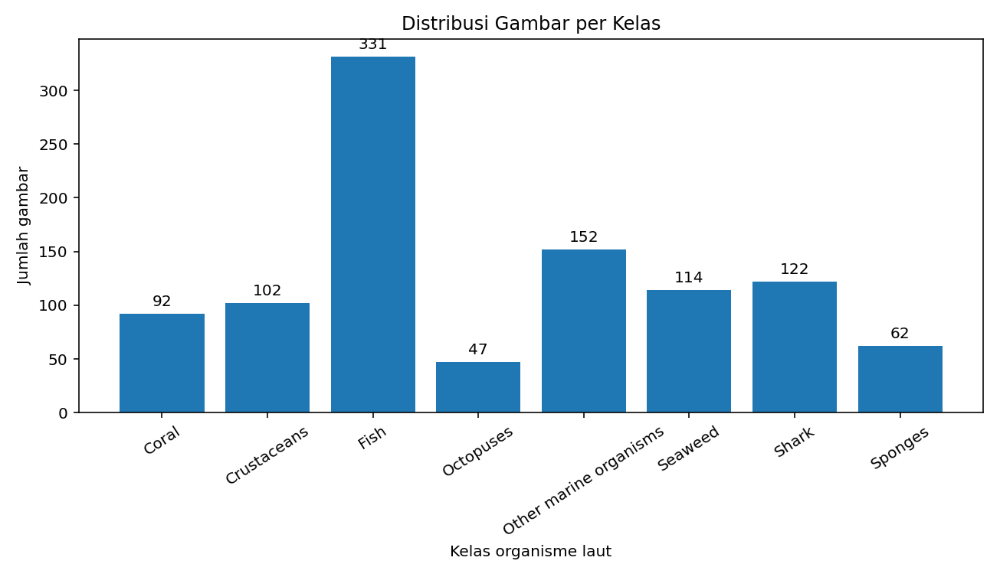


 Contoh gambar tiap kelas


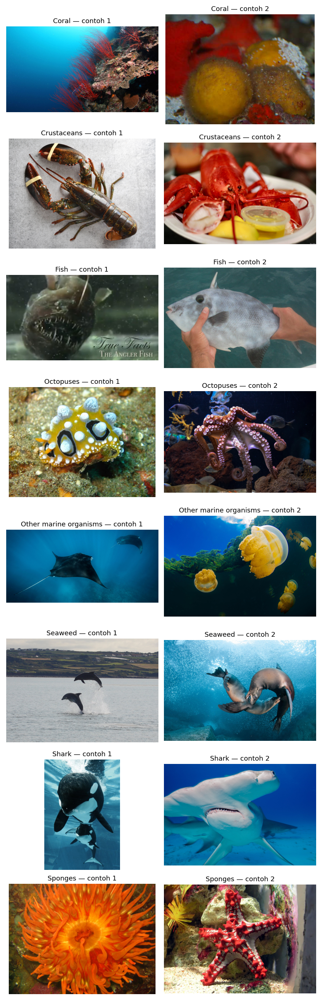


 Ukuran gambar


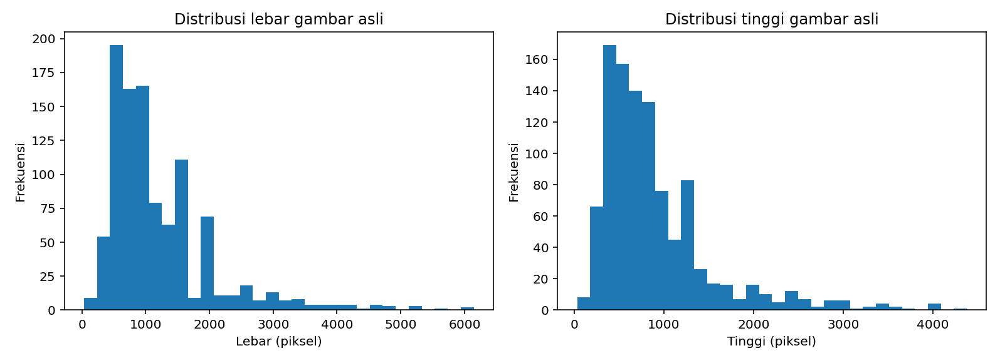


 Indikasi kualitas


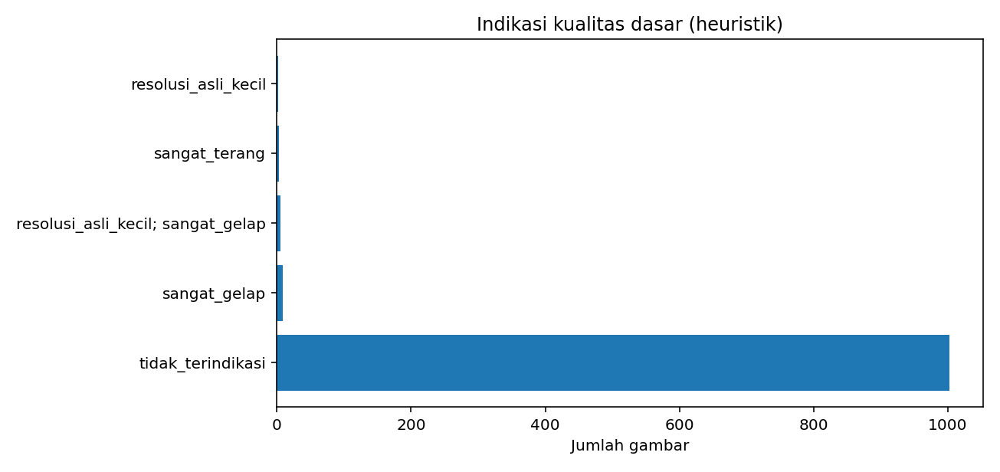

In [11]:
from IPython.display import display as show
counts = df['kelas'].value_counts().sort_index()
display(counts.rename_axis('Kelas').reset_index(name='Jumlah gambar'))
print('Ukuran gambar - statistik:')
display(df[['lebar_asli','tinggi_asli']].describe().round(2))
print('Mode warna:', df['mode_asli'].value_counts().to_dict())
rasio_kelas = float(counts.max()/counts.min())
print('Rasio kelas terbesar/terkecil:', round(rasio_kelas, 2))
print('Analisis:', 'Dataset tidak seimbang; class weight akan dipertimbangkan.' if rasio_kelas > 1.5
      else 'Keseimbangan antarkelas relatif baik menurut rasio sederhana.')
save_eda(df, OUT_DIR)
for name, title in [('distribusi_kelas.png','Distribusi kelas'),
                    ('contoh_tiap_kelas.png','Contoh gambar tiap kelas'),
                    ('ukuran_gambar.png','Ukuran gambar'),
                    ('indikasi_kualitas.png','Indikasi kualitas')]:
    print('\n',title)
    display(IPyImage(filename=str(OUT_DIR/name), width=800))

### Interpretasi EDA
- **Distribusi kelas:** kelas dengan jumlah lebih kecil berpotensi lebih sulit dipelajari model.
- **Contoh gambar:** amati bentuk tubuh, latar belakang, warna, perspektif, dan kemiripan antarkelas.
- **Ukuran gambar:** ukuran asli yang beragam diseragamkan sebelum masuk CNN.
- **Indikasi kualitas:** gambar sangat gelap/terang atau resolusi kecil perlu diperiksa secara visual; grafik ini menggunakan aturan sederhana, bukan penilaian biologis.

## Langkah 3 — Pra-pemrosesan data
Resize menjadi ukuran seragam, konversi RGB, normalisasi 0–1 di lapisan model, integer encoding label, pembagian stratifikasi **80% train, 10% validation, 10% test**. Random augmentation hanya aktif saat training. Deduplicasi gambar identik dilakukan **sebelum** split agar mengurangi kebocoran antara training dan testing.

In [12]:
df = stratified_split(df)
classes = sorted(df['kelas'].unique(), key=str.casefold)
mapping = {c:i for i,c in enumerate(classes)}
frames = {name:df[df['split']==name].reset_index(drop=True) for name in ('train','validation','test')}
df['label_numerik'] = df['kelas'].map(mapping).astype(int)
df.to_csv(OUT_DIR/'dataset_metadata.csv', index=False)
print('Encoding label:', mapping)
print('Total:',len(df),'| Train:',len(frames['train']),
      '| Validation:',len(frames['validation']),'| Test:',len(frames['test']))
print('Proporsi (%)',df['split'].value_counts(normalize=True).mul(100).round(2).to_dict())
display(pd.crosstab(df['kelas'],df['split']))
import tensorflow as tf
tf.keras.utils.set_random_seed(SEED)
train_ds=make_tf_dataset(frames['train'],mapping,IMG_SIZE,BATCH_SIZE,training=True)
val_ds=make_tf_dataset(frames['validation'],mapping,IMG_SIZE,BATCH_SIZE)
test_ds=make_tf_dataset(frames['test'],mapping,IMG_SIZE,BATCH_SIZE)

Encoding label: {'Coral': 0, 'Crustaceans': 1, 'Fish': 2, 'Octopuses': 3, 'Other marine organisms': 4, 'Seaweed': 5, 'Shark': 6, 'Sponges': 7}
Total: 1022 | Train: 817 | Validation: 102 | Test: 103
Proporsi (%) {'train': 79.94, 'test': 10.08, 'validation': 9.98}


split,test,train,validation
kelas,,,
Coral,9,74,9
Crustaceans,10,81,11
Fish,33,265,33
Octopuses,4,38,5
Other marine organisms,16,121,15
Seaweed,12,91,11
Shark,13,97,12
Sponges,6,50,6


In [18]:

# LANGKAH 3 - PRA-PEMROSESAN DATASET

import tensorflow as tf
import pandas as pd
import numpy as np
from IPython.display import display

# Parameter
IMG_SIZE = 128
BATCH_SIZE = 32

tf.keras.utils.set_random_seed(SEED)

# 1. Pembagian data secara stratified
# Training 80%, Validation 10%, Testing 10%
df = stratified_split(df)

# 2. Encoding label menjadi angka
classes = sorted(df["kelas"].unique(), key=str.casefold)
mapping = {nama: i for i, nama in enumerate(classes)}

df["label_numerik"] = df["kelas"].map(mapping).astype(int)

print("Encoding kelas:")
for nama, nomor in mapping.items():
    print(f"{nomor} = {nama}")

# 3. Memisahkan data berdasarkan split
frames = {
    nama: df[df["split"] == nama].reset_index(drop=True)
    for nama in ["train", "validation", "test"]
}

# 4. Menampilkan jumlah data
print("\nJumlah dataset:")
print("Training  :", len(frames["train"]))
print("Validation:", len(frames["validation"]))
print("Testing   :", len(frames["test"]))
print("Total     :", len(df))

print("\nProporsi pembagian (%):")
print(
    df["split"].value_counts(normalize=True)
    .mul(100).round(2)
)

# 5. Distribusi setiap kelas
display(pd.crosstab(df["kelas"], df["split"]))

# 6. Menyiapkan TensorFlow dataset
train_ds = make_tf_dataset(
    frames["train"], mapping,
    IMG_SIZE, BATCH_SIZE, training=True
)

val_ds = make_tf_dataset(
    frames["validation"], mapping,
    IMG_SIZE, BATCH_SIZE
)

test_ds = make_tf_dataset(
    frames["test"], mapping,
    IMG_SIZE, BATCH_SIZE
)

# 7. Simpan metadata dataset
df.to_csv(
    OUT_DIR / "dataset_metadata.csv",
    index=False
)

print("\nPreprocessing berhasil!")
print("Ukuran gambar:", IMG_SIZE, "x", IMG_SIZE)
print("Jumlah kelas:", len(classes))

# Cek bentuk gambar dan label
for images, labels in train_ds.take(1):
    print("Shape gambar:", images.shape)
    print("Shape label :", labels.shape)
    print("Tipe data  :", images.dtype)


Encoding kelas:
0 = Coral
1 = Crustaceans
2 = Fish
3 = Octopuses
4 = Other marine organisms
5 = Seaweed
6 = Shark
7 = Sponges

Jumlah dataset:
Training  : 817
Validation: 102
Testing   : 103
Total     : 1022

Proporsi pembagian (%):
split
train         79.94
test          10.08
validation     9.98
Name: proportion, dtype: float64


split,test,train,validation
kelas,,,
Coral,9,74,9
Crustaceans,10,81,11
Fish,33,265,33
Octopuses,4,38,5
Other marine organisms,16,121,15
Seaweed,12,91,11
Shark,13,97,12
Sponges,6,50,6



Preprocessing berhasil!
Ukuran gambar: 128 x 128
Jumlah kelas: 8
Shape gambar: (32, 128, 128, 3)
Shape label : (32,)
Tipe data  : <dtype: 'float32'>


2026-10-31 12:11:28.224836: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


## Langkah 4 — Membangun dan melatih CNN
CNN: `Rescaling(1/255)` → augmentasi (flip/rotasi/zoom/geser) → tiga blok Conv2D (32,64,128 filter) + BatchNormalization + MaxPooling → GlobalAveragePooling → Dense(128, ReLU) → Dropout → Softmax. Optimizer Adam, learning rate 0.001, 15 epoch maksimum, batch size 32. Simpan model `.keras` terbaik berdasarkan `val_loss`.

In [19]:

# =====================================================
# LANGKAH 4 - PEMBANGUNAN DAN PELATIHAN MODEL CNN
# OCEANIC LIFE DATASET
# =====================================================

import tensorflow as tf
import pandas as pd
from pathlib import Path

# 1. Parameter pelatihan
EPOCHS = 15
BATCH_SIZE = 32
LEARNING_RATE = 0.001

print("Jumlah kelas:", len(classes))
print("Ukuran gambar:", IMG_SIZE)
print("Epoch:", EPOCHS)
print("Batch size:", BATCH_SIZE)

# 2. Membangun arsitektur CNN
model = build_cnn(
    num_classes=len(classes),
    img_size=IMG_SIZE,
    lr=LEARNING_RATE
)

# Menampilkan arsitektur model
model.summary()

# 3. Mengatasi ketidakseimbangan kelas
train_counts = frames["train"]["kelas"].value_counts()

class_weights = None

if train_counts.max() / train_counts.min() > 1.5:
    class_weights = {
        mapping[c]: len(frames["train"]) /
        (len(classes) * train_counts[c])
        for c in classes
    }

print("\nClass weights:", class_weights)

# 4. Menentukan lokasi penyimpanan model
MODEL_PATH = OUT_DIR / "model_oceanic_cnn.keras"

# 5. Callback pelatihan
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

# 6. Training CNN
print("\nMemulai proses training CNN...")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    class_weight=class_weights,
    verbose=1
)

# 7. Menyimpan riwayat pelatihan
history_df = pd.DataFrame(history.history)

history_df.to_csv(
    OUT_DIR / "history.csv",
    index=False
)

# 8. Memuat model terbaik
model = tf.keras.models.load_model(MODEL_PATH)

# 9. Menampilkan ringkasan hasil training
print("\n========== HASIL TRAINING ==========")

print("Epoch dijalankan:", len(history_df))

print(
    "Training Accuracy terakhir:",
    round(history_df["accuracy"].iloc[-1], 4)
)

print(
    "Validation Accuracy terakhir:",
    round(history_df["val_accuracy"].iloc[-1], 4)
)

print(
    "Validation Loss terbaik:",
    round(history_df["val_loss"].min(), 4)
)

print("\nModel terbaik tersimpan di:")
print(MODEL_PATH)

print("\nTraining CNN selesai!")


Jumlah kelas: 8
Ukuran gambar: 128
Epoch: 15
Batch size: 32


Model: "oceanic_life_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gambar_rgb (InputLayer)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalisasi_0_1 (Rescaling)     │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment_flip (RandomFlip)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment_rotasi (RandomRotation) │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment_zoom (RandomZoom)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment_shift                   │ (None, 128, 128, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prediksi (Dense)                │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,688 (436.28 KB)

 Trainable params: 111,240 (434.53 KB)

 Non-trainable params: 448 (1.75 KB)


Class weights: {0: 1.3800675675675675, 1: 1.2608024691358024, 2: 0.38537735849056604, 3: 2.6875, 4: 0.84400826446281, 5: 1.1222527472527473, 6: 1.0528350515463918, 7: 2.0425}

Memulai proses training CNN...
Epoch 1/15


/opt/miniconda3/envs/ds/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 260ms/step - accuracy: 0.2191 - loss: 2.0559
Epoch 1: val_loss improved from None to 2.05392, saving model to /Users/mochammadmarillivio/Downloads/Oceanic_Life_CNN_PERBAIKAN_FOLDER/output/model_oceanic_cnn.keras

Epoch 1: finished saving model to /Users/mochammadmarillivio/Downloads/Oceanic_Life_CNN_PERBAIKAN_FOLDER/output/model_oceanic_cnn.keras
26/26 ━━━━━━━━━━━━━━━━━━━━ 9s 274ms/step - accuracy: 0.2191 - loss: 2.0559 - val_accuracy: 0.0882 - val_loss: 2.0539 - learning_rate: 0.0010
Epoch 2/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 268ms/step - accuracy: 0.2876 - loss: 1.8873
Epoch 2: val_loss improved from 2.05392 to 2.03337, saving model to /Users/mochammadmarillivio/Downloads/Oceanic_Life_CNN_PERBAIKAN_FOLDER/output/model_oceanic_cnn.keras

Epoch 2: finished saving model to /Users/mochammadmarillivio/Downloads/Oceanic_Life_CNN_PERBAIKAN_FOLDER/output/model_oceanic_cnn.keras
26/26 ━━━━━━━━━━━━━━━━━━━━ 7s 277ms/step - accuracy: 0.2876 - loss: 1.8873 - val_accura

In [13]:
model=build_cnn(num_classes=len(classes),img_size=IMG_SIZE,lr=LEARNING_RATE)
model.summary()
train_counts=frames['train']['kelas'].value_counts()
class_weights=None
if train_counts.max()/train_counts.min() > 1.5:
    class_weights={mapping[c]: len(frames['train'])/(len(classes)*train_counts[c]) for c in classes}
print('Class weight:',class_weights)
callbacks=[
    tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=4,restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(str(OUT_DIR/'model_oceanic_cnn.keras'),
                                       monitor='val_loss',save_best_only=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',factor=0.5,patience=2,min_lr=1e-6),
]
history=model.fit(train_ds,validation_data=val_ds,epochs=EPOCHS,
                  callbacks=callbacks,class_weight=class_weights,verbose=1)
h=pd.DataFrame(history.history)
h.to_csv(OUT_DIR/'history.csv',index=False)
model=tf.keras.models.load_model(OUT_DIR/'model_oceanic_cnn.keras')
print('Model tersimpan:',OUT_DIR/'model_oceanic_cnn.keras')

Model: "oceanic_life_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gambar_rgb (InputLayer)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalisasi_0_1 (Rescaling)     │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment_flip (RandomFlip)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment_rotasi (RandomRotation) │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment_zoom (RandomZoom)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment_shift                   │ (None, 128, 128, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prediksi (Dense)                │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,688 (436.28 KB)

 Trainable params: 111,240 (434.53 KB)

 Non-trainable params: 448 (1.75 KB)

Class weight: {0: 1.3800675675675675, 1: 1.2608024691358024, 2: 0.38537735849056604, 3: 2.6875, 4: 0.84400826446281, 5: 1.1222527472527473, 6: 1.0528350515463918, 7: 2.0425}
Epoch 1/15


/opt/miniconda3/envs/ds/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


26/26 ━━━━━━━━━━━━━━━━━━━━ 8s 277ms/step - accuracy: 0.2044 - loss: 2.0737 - val_accuracy: 0.1275 - val_loss: 2.0399 - learning_rate: 0.0010
Epoch 2/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 7s 282ms/step - accuracy: 0.2668 - loss: 1.9369 - val_accuracy: 0.1176 - val_loss: 2.0320 - learning_rate: 0.0010
Epoch 3/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 7s 279ms/step - accuracy: 0.2754 - loss: 1.8394 - val_accuracy: 0.1176 - val_loss: 2.0577 - learning_rate: 0.0010
Epoch 4/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 7s 265ms/step - accuracy: 0.2632 - loss: 1.8398 - val_accuracy: 0.1275 - val_loss: 2.1071 - learning_rate: 0.0010
Epoch 5/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 7s 250ms/step - accuracy: 0.3415 - loss: 1.7367 - val_accuracy: 0.1176 - val_loss: 2.1441 - learning_rate: 5.0000e-04
Epoch 6/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 7s 258ms/step - accuracy: 0.3464 - loss: 1.6920 - val_accuracy: 0.1176 - val_loss: 2.2764 - learning_rate: 5.0000e-04
Model tersimpan: /Users/mochammadmarillivio/Downloads/Oceanic_Life_CNN_PERBAIKAN_FOLDER/out

## Langkah 5 — Evaluasi model pada test set
Data testing belum dipakai untuk memperbarui bobot ataupun memilih epoch. Hitung Accuracy, Precision, Recall, F1-Score (weighted dan macro); analisis metrik per kelas.

In [20]:

# =====================================================
# LANGKAH 5 - EVALUASI MODEL CNN
# OCEANIC LIFE DATASET
# =====================================================

import numpy as np
import pandas as pd
import json
import tensorflow as tf
from IPython.display import display

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Memuat model terbaik dari Langkah 4
MODEL_PATH = OUT_DIR / "model_oceanic_cnn.keras"

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        "Model belum ditemukan. Jalankan Langkah 4 dahulu."
    )

model = tf.keras.models.load_model(MODEL_PATH)

print("Model berhasil dimuat!")
print("Lokasi:", MODEL_PATH)

# 2. Mengevaluasi model menggunakan data testing
print("\n========== EVALUASI DATA TEST ==========")

test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)

print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")

# 3. Melakukan prediksi pada data testing
print("\nMelakukan prediksi gambar testing...")

probs = model.predict(
    test_ds,
    verbose=1
)

# Mengambil kelas dengan probabilitas tertinggi
y_pred = np.argmax(probs, axis=1)

# Label sebenarnya sesuai urutan test_ds
# Dataset testing tidak di-shuffle
y_true = (
    frames["test"]["kelas"]
    .map(mapping)
    .to_numpy(dtype=int)
)

assert len(y_true) == len(y_pred), (
    "Jumlah prediksi tidak sesuai dengan jumlah label test."
)

# 4. Menghitung Accuracy
accuracy = accuracy_score(y_true, y_pred)

# 5. Menghitung Precision
precision = precision_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

# 6. Menghitung Recall
recall = recall_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

# 7. Menghitung F1-Score
f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

# 8. Macro F1-Score
macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

# 9. Ringkasan evaluasi
hasil_evaluasi = pd.DataFrame({
    "Metrik": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "Macro F1-Score"
    ],
    "Nilai": [
        accuracy,
        precision,
        recall,
        f1,
        macro_f1
    ]
})

hasil_evaluasi["Persentase (%)"] = (
    hasil_evaluasi["Nilai"] * 100
).round(2)

print("\n========== HASIL EVALUASI CNN ==========")
display(hasil_evaluasi)

# 10. Classification report per kelas
print("\n========== EVALUASI PER KELAS ==========")

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(classes))),
    target_names=classes,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T

display(report_df.round(4))

# 11. Analisis kelas dengan F1 tertinggi dan terendah
f1_per_kelas = report_df.loc[
    classes, "f1-score"
]

kelas_terbaik = f1_per_kelas.idxmax()
kelas_tersulit = f1_per_kelas.idxmin()

print("\n========== ANALISIS MODEL ==========")

print(
    "Kelas dengan F1 tertinggi:",
    kelas_terbaik,
    f"({f1_per_kelas.max():.4f})"
)

print(
    "Kelas dengan F1 terendah:",
    kelas_tersulit,
    f"({f1_per_kelas.min():.4f})"
)

print(
    f"\nJumlah prediksi benar: "
    f"{np.sum(y_true == y_pred)}"
)

print(
    f"Jumlah prediksi salah: "
    f"{np.sum(y_true != y_pred)}"
)

# 12. Menyimpan hasil evaluasi
hasil_evaluasi.to_csv(
    OUT_DIR / "hasil_evaluasi.csv",
    index=False
)

report_df.to_csv(
    OUT_DIR / "classification_report.csv",
    index_label="kelas"
)

metrics = {
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1_score": float(f1),
    "macro_f1": float(macro_f1),
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy)
}

with open(
    OUT_DIR / "metrics.json", "w",
    encoding="utf-8"
) as file:
    json.dump(metrics, file, indent=4)

# 13. Menyiapkan confusion matrix untuk Langkah 6
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(classes)))
)

print("\nSemua hasil evaluasi berhasil disimpan!")
print("Lokasi output:", OUT_DIR)
print("\nLangkah 5 selesai!")


Model berhasil dimuat!
Lokasi: /Users/mochammadmarillivio/Downloads/Oceanic_Life_CNN_PERBAIKAN_FOLDER/output/model_oceanic_cnn.keras

========== EVALUASI DATA TEST ==========
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.1456 - loss: 2.0263
Test Loss     : 2.0263
Test Accuracy : 0.1456

Melakukan prediksi gambar testing...
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step

========== HASIL EVALUASI CNN ==========


,Metrik,Nilai,Persentase (%)
0,Accuracy,0.145631,14.56
1,Precision,0.228717,22.87
2,Recall,0.145631,14.56
3,F1-Score,0.064223,6.42
4,Macro F1-Score,0.049580,4.96



========== EVALUASI PER KELAS ==========


,precision,recall,f1-score,support
Coral,0.0000,0.0000,0.0000,9.0000
Crustaceans,0.0000,0.0000,0.0000,10.0000
Fish,0.5000,0.0303,0.0571,33.0000
Octopuses,0.0000,0.0000,0.0000,4.0000
Other marine organisms,0.3333,0.0625,0.1053,16.0000
Seaweed,0.0000,0.0000,0.0000,12.0000
Shark,0.1327,1.0000,0.2342,13.0000
Sponges,0.0000,0.0000,0.0000,6.0000
accuracy,0.1456,0.1456,0.1456,0.1456
macro avg,0.1207,0.1366,0.0496,103.0000



========== ANALISIS MODEL ==========
Kelas dengan F1 tertinggi: Shark (0.2342)
Kelas dengan F1 terendah: Coral (0.0000)

Jumlah prediksi benar: 15
Jumlah prediksi salah: 88

Semua hasil evaluasi berhasil disimpan!
Lokasi output: /Users/mochammadmarillivio/Downloads/Oceanic_Life_CNN_PERBAIKAN_FOLDER/output

Langkah 5 selesai!


In [14]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
probs=model.predict(test_ds,verbose=1)
y_true=frames['test']['kelas'].map(mapping).to_numpy(dtype=int)
y_pred=np.argmax(probs,axis=1)
p,r,f,_=precision_recall_fscore_support(y_true,y_pred,average='weighted',zero_division=0)
mp,mr,mf,_=precision_recall_fscore_support(y_true,y_pred,average='macro',zero_division=0)
metrics={'accuracy':float(accuracy_score(y_true,y_pred)), 'precision':float(p),
         'recall':float(r),'f1_score':float(f),'macro_precision':float(mp),
         'macro_recall':float(mr),'macro_f1':float(mf),
         'rerata_confidence_prediksi':float(np.max(probs,axis=1).mean())}
(OUT_DIR/'metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
report=classification_report(y_true,y_pred,labels=list(range(len(classes))),
                             target_names=classes,output_dict=True,zero_division=0)
report_df=pd.DataFrame(report).T
report_df.to_csv(OUT_DIR/'classification_report.csv',index_label='kelas')
print('Ringkasan evaluasi DATA TEST:')
display(pd.DataFrame([metrics])[['accuracy','precision','recall','f1_score','macro_f1']].round(4))
display(report_df.round(3))
print('Kelas dengan F1 paling rendah:',report_df.loc[classes,'f1-score'].idxmin())

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
Ringkasan evaluasi DATA TEST:


,accuracy,precision,recall,f1_score,macro_f1
0,0.1359,0.0939,0.1359,0.046,0.0424


,precision,recall,f1-score,support
Coral,0.000,0.000,0.000,9.000
Crustaceans,0.000,0.000,0.000,10.000
Fish,0.000,0.000,0.000,33.000
Octopuses,0.000,0.000,0.000,4.000
Other marine organisms,0.500,0.062,0.111,16.000
Seaweed,0.000,0.000,0.000,12.000
Shark,0.129,1.000,0.228,13.000
Sponges,0.000,0.000,0.000,6.000
accuracy,0.136,0.136,0.136,0.136
macro avg,0.079,0.133,0.042,103.000


Kelas dengan F1 paling rendah: Coral


## Langkah 6 — Visualisasi hasil
Buat confusion matrix, kurva train/validation accuracy dan loss, contoh gambar tes dengan label asli dan hasil prediksi, dan **Grad-CAM** (area gambar yang berkaitan dengan keluaran CNN, bukan kepastian penyebab keputusan).

1. VISUALISASI ACCURACY DAN LOSS


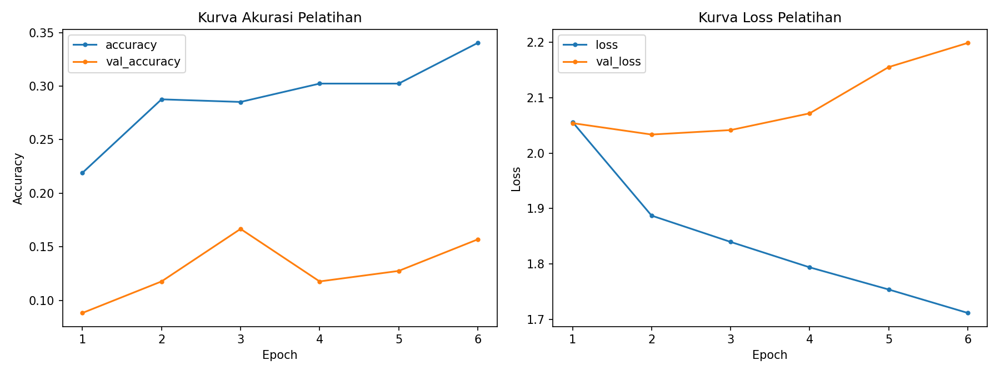

Epoch dengan validation loss terbaik: 2
Validation accuracy tertinggi: 16.67 %
Validation loss terendah: 2.0334

2. VISUALISASI CONFUSION MATRIX


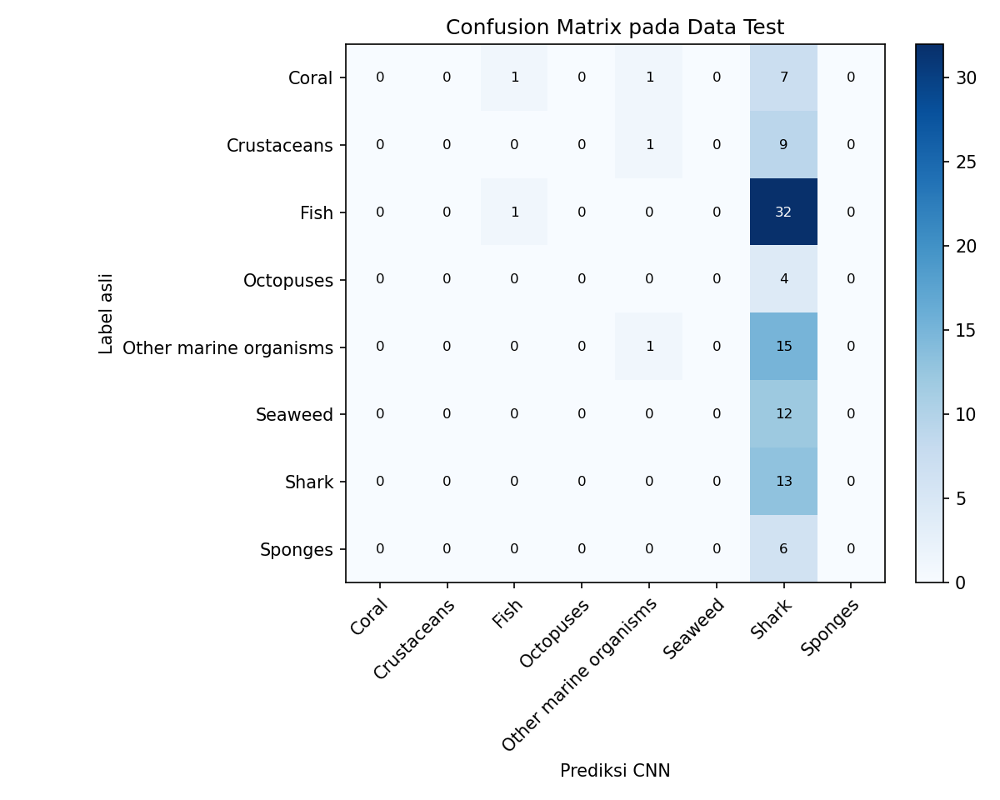

,Kelas,Jumlah Gambar Test,Prediksi Benar,Prediksi Salah,Recall (%)
0,Coral,9,0,9,0.00
1,Crustaceans,10,0,10,0.00
2,Fish,33,1,32,3.03
3,Octopuses,4,0,4,0.00
4,Other marine organisms,16,1,15,6.25
5,Seaweed,12,0,12,0.00
6,Shark,13,13,0,100.00
7,Sponges,6,0,6,0.00



Kesalahan klasifikasi terbanyak:
Kelas sebenarnya : Fish
Diprediksi sebagai: Shark
Jumlah kesalahan : 32

3. VISUALISASI PREDIKSI GAMBAR


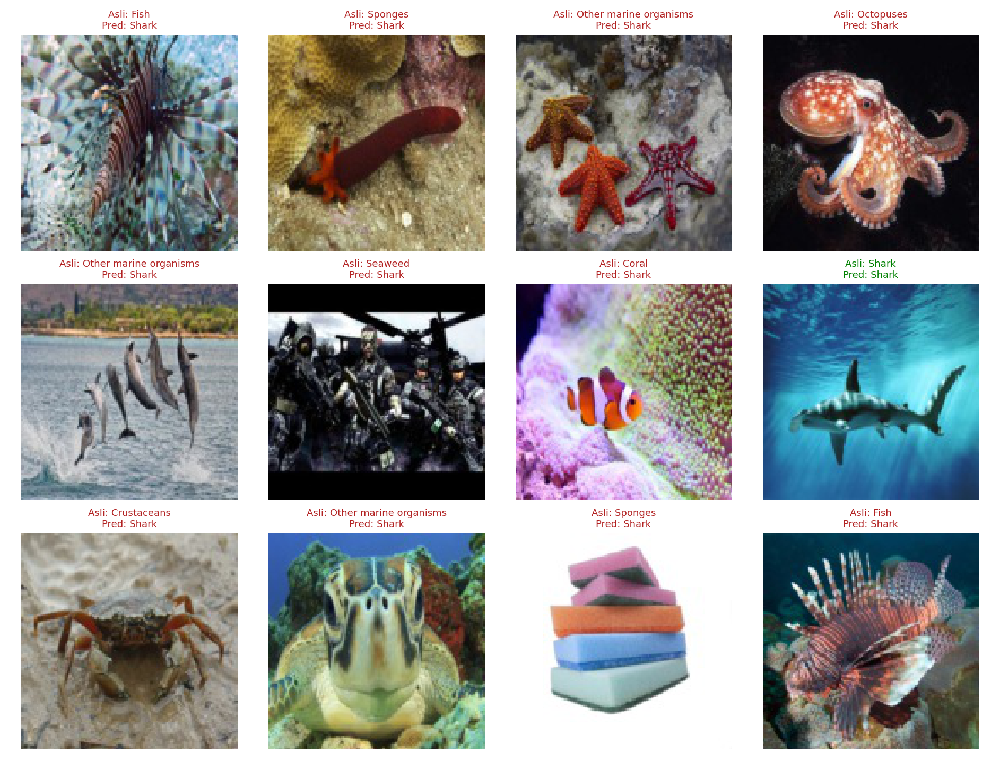


Analisis contoh prediksi:

Gambar 1
Kelas label : Sponges
Prediksi CNN: Shark
Confidence  : 15.79%
Analisis: Prediksi berbeda dari label dataset. Kemungkinan terdapat kemiripan visual, keterbatasan model, atau kesalahan label.

Gambar 2
Kelas label : Other marine organisms
Prediksi CNN: Shark
Confidence  : 19.34%
Analisis: Prediksi berbeda dari label dataset. Kemungkinan terdapat kemiripan visual, keterbatasan model, atau kesalahan label.

Gambar 3
Kelas label : Shark
Prediksi CNN: Shark
Confidence  : 18.83%
Analisis: Prediksi sesuai dengan label dataset.

Gambar 4
Kelas label : Other marine organisms
Prediksi CNN: Shark
Confidence  : 18.61%
Analisis: Prediksi berbeda dari label dataset. Kemungkinan terdapat kemiripan visual, keterbatasan model, atau kesalahan label.

Gambar 5
Kelas label : Sponges
Prediksi CNN: Shark
Confidence  : 20.13%
Analisis: Prediksi berbeda dari label dataset. Kemungkinan terdapat kemiripan visual, keterbatasan model, atau kesalahan label.

Gambar 6
Kelas labe

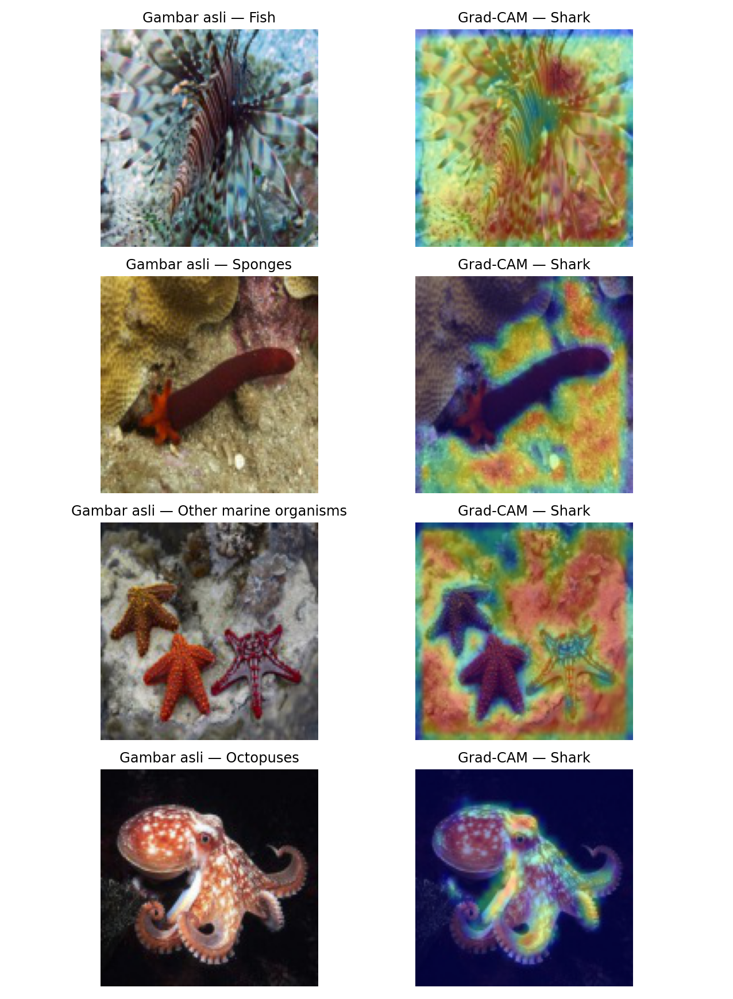

Grad-CAM menunjukkan area gambar yang berkontribusi terhadap prediksi CNN.
Area berwarna hangat menunjukkan kontribusi relatif lebih tinggi pada visualisasi tersebut.

========== HASIL LANGKAH 6 ==========
Jumlah gambar test: 103
Prediksi benar: 15
Prediksi salah: 88

File visualisasi tersimpan:
akurasi_loss.png - Berhasil
confusion_matrix.png - Berhasil
confusion_matrix.csv - Berhasil
analisis_confusion_matrix.csv - Berhasil
prediksi_sampel_test.png - Berhasil
prediksi_data_test.csv - Berhasil
gradcam_sampel.png - Berhasil

Langkah 6 selesai!


In [21]:

# =====================================================
# LANGKAH 6 - VISUALISASI HASIL CNN
# OCEANIC LIFE DATASET
# =====================================================

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import confusion_matrix
from IPython.display import display, Image as IPyImage

OUT_DIR = Path(OUT_DIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# =====================================================
# 1. GRAFIK ACCURACY DAN LOSS
# =====================================================

print("1. VISUALISASI ACCURACY DAN LOSS")

# Mengambil riwayat training dari Langkah 4
history_path = OUT_DIR / "history.csv"

if history_path.exists():
    history_data = pd.read_csv(history_path)
elif "history_df" in globals():
    history_data = history_df.copy()
elif "h" in globals():
    history_data = h.copy()
else:
    history_data = pd.DataFrame(history.history)

# Membuat grafik training dan validation
plot_history(history_data, OUT_DIR)

display(
    IPyImage(
        filename=str(OUT_DIR / "akurasi_loss.png"),
        width=900
    )
)

best_epoch = int(history_data["val_loss"].idxmin()) + 1

print("Epoch dengan validation loss terbaik:", best_epoch)

print(
    "Validation accuracy tertinggi:",
    round(history_data["val_accuracy"].max() * 100, 2),
    "%"
)

print(
    "Validation loss terendah:",
    round(history_data["val_loss"].min(), 4)
)

# =====================================================
# 2. CONFUSION MATRIX
# =====================================================

print("\n2. VISUALISASI CONFUSION MATRIX")

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(classes)))
)

# Simpan confusion matrix dalam PNG dan CSV
save_matrix(cm, classes, OUT_DIR)

display(
    IPyImage(
        filename=str(OUT_DIR / "confusion_matrix.png"),
        width=900
    )
)

# Analisis akurasi masing-masing kelas
jumlah_per_kelas = cm.sum(axis=1)
benar_per_kelas = np.diag(cm)

akurasi_per_kelas = np.divide(
    benar_per_kelas,
    jumlah_per_kelas,
    out=np.zeros(len(classes), dtype=float),
    where=jumlah_per_kelas != 0
)

analisis_kelas = pd.DataFrame({
    "Kelas": classes,
    "Jumlah Gambar Test": jumlah_per_kelas,
    "Prediksi Benar": benar_per_kelas,
    "Prediksi Salah": jumlah_per_kelas - benar_per_kelas,
    "Recall (%)": np.round(akurasi_per_kelas * 100, 2)
})

display(analisis_kelas)

analisis_kelas.to_csv(
    OUT_DIR / "analisis_confusion_matrix.csv",
    index=False
)

# Identifikasi kesalahan paling sering
kesalahan = cm.copy()
np.fill_diagonal(kesalahan, 0)

if kesalahan.max() > 0:
    i, j = np.unravel_index(
        np.argmax(kesalahan),
        kesalahan.shape
    )

    print("\nKesalahan klasifikasi terbanyak:")
    print("Kelas sebenarnya :", classes[i])
    print("Diprediksi sebagai:", classes[j])
    print("Jumlah kesalahan :", kesalahan[i, j])
else:
    print("Tidak terdapat kesalahan pada data test.")

# =====================================================
# 3. VISUALISASI PREDIKSI GAMBAR TESTING
# =====================================================

print("\n3. VISUALISASI PREDIKSI GAMBAR")

# Dataset test tidak di-shuffle sehingga urutannya
# sesuai dengan hasil prediksi Langkah 5.
examples = frames["test"][
    ["path_asli", "path_cache", "kelas"]
].copy()

examples["prediksi"] = [
    classes[i] for i in y_pred
]

examples["confidence"] = np.max(probs, axis=1)

examples["benar"] = (
    examples["kelas"] == examples["prediksi"]
)

examples.to_csv(
    OUT_DIR / "prediksi_data_test.csv",
    index=False
)

# Membuat gambar prediksi beserta Grad-CAM
samples_visualization(
    frames["test"],
    classes,
    y_true,
    y_pred,
    model,
    IMG_SIZE,
    OUT_DIR
)

display(
    IPyImage(
        filename=str(OUT_DIR / "prediksi_sampel_test.png"),
        width=950
    )
)

# Menampilkan analisis beberapa gambar
print("\nAnalisis contoh prediksi:")

rng = np.random.default_rng(42)

sample_ids = rng.choice(
    len(examples),
    size=min(8, len(examples)),
    replace=False
)

for nomor, idx in enumerate(sample_ids, start=1):
    row = examples.iloc[idx]

    print(f"\nGambar {nomor}")
    print("Kelas label :", row["kelas"])
    print("Prediksi CNN:", row["prediksi"])
    print(
        "Confidence  :",
        f'{row["confidence"] * 100:.2f}%'
    )

    if row["benar"]:
        print("Analisis: Prediksi sesuai dengan label dataset.")
    else:
        print(
            "Analisis: Prediksi berbeda dari label dataset. "
            "Kemungkinan terdapat kemiripan visual, "
            "keterbatasan model, atau kesalahan label."
        )

# =====================================================
# 4. GRAD-CAM / FEATURE IMPORTANCE
# =====================================================

print("\n4. VISUALISASI GRAD-CAM")

display(
    IPyImage(
        filename=str(OUT_DIR / "gradcam_sampel.png"),
        width=900
    )
)

print(
    "Grad-CAM menunjukkan area gambar yang "
    "berkontribusi terhadap prediksi CNN."
)

print(
    "Area berwarna hangat menunjukkan kontribusi "
    "relatif lebih tinggi pada visualisasi tersebut."
)

# =====================================================
# 5. RINGKASAN HASIL
# =====================================================

print("\n========== HASIL LANGKAH 6 ==========")

print("Jumlah gambar test:", len(y_true))
print("Prediksi benar:", int(np.sum(y_true == y_pred)))
print("Prediksi salah:", int(np.sum(y_true != y_pred)))

print("\nFile visualisasi tersimpan:")

files = [
    "akurasi_loss.png",
    "confusion_matrix.png",
    "confusion_matrix.csv",
    "analisis_confusion_matrix.csv",
    "prediksi_sampel_test.png",
    "prediksi_data_test.csv",
    "gradcam_sampel.png"
]

for nama in files:
    path = OUT_DIR / nama
    print(
        nama,
        "-",
        "Berhasil" if path.exists() else "Belum tersedia"
    )

print("\nLangkah 6 selesai!")



Visualisasi: akurasi_loss.png


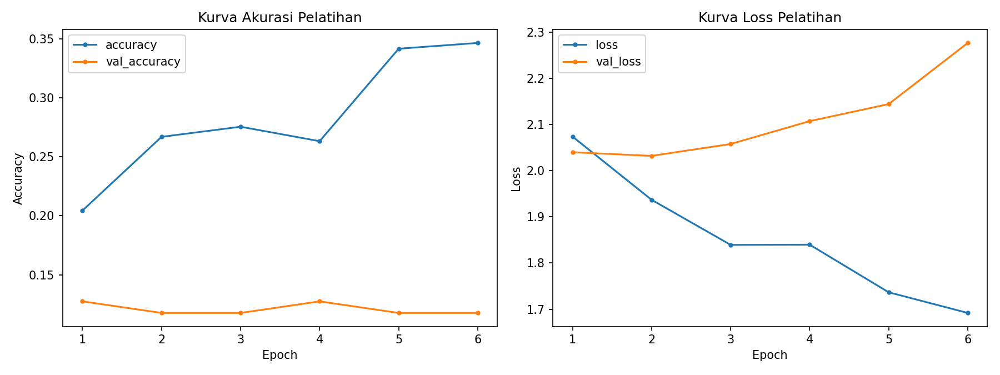


Visualisasi: confusion_matrix.png


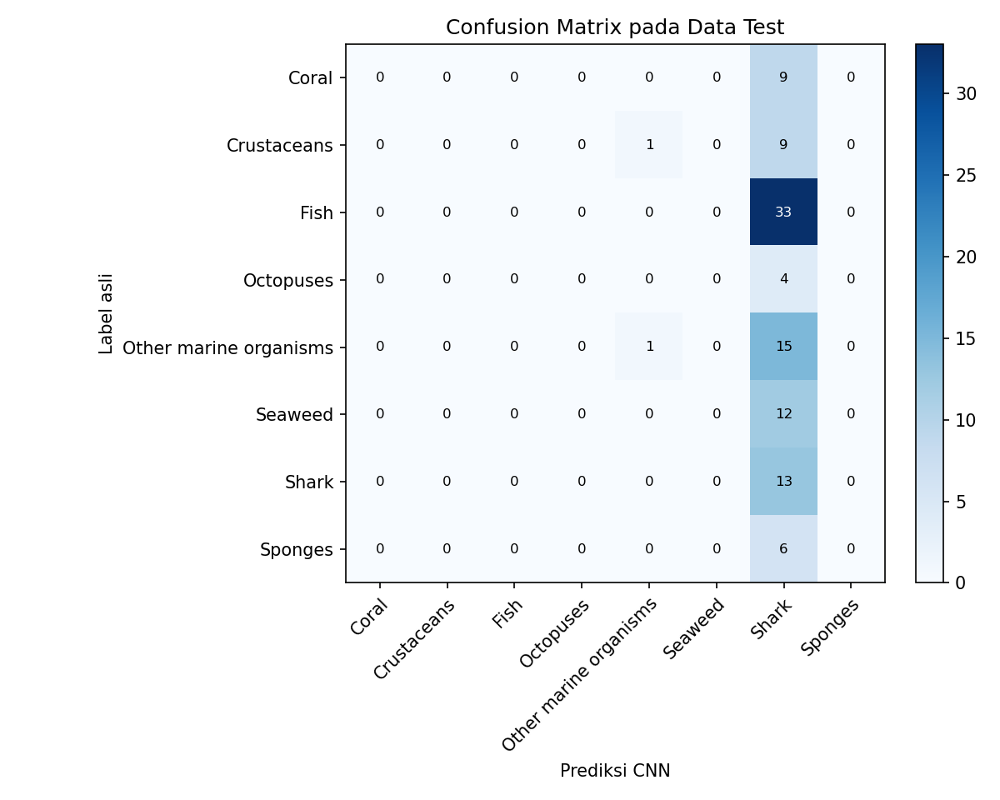


Visualisasi: prediksi_sampel_test.png


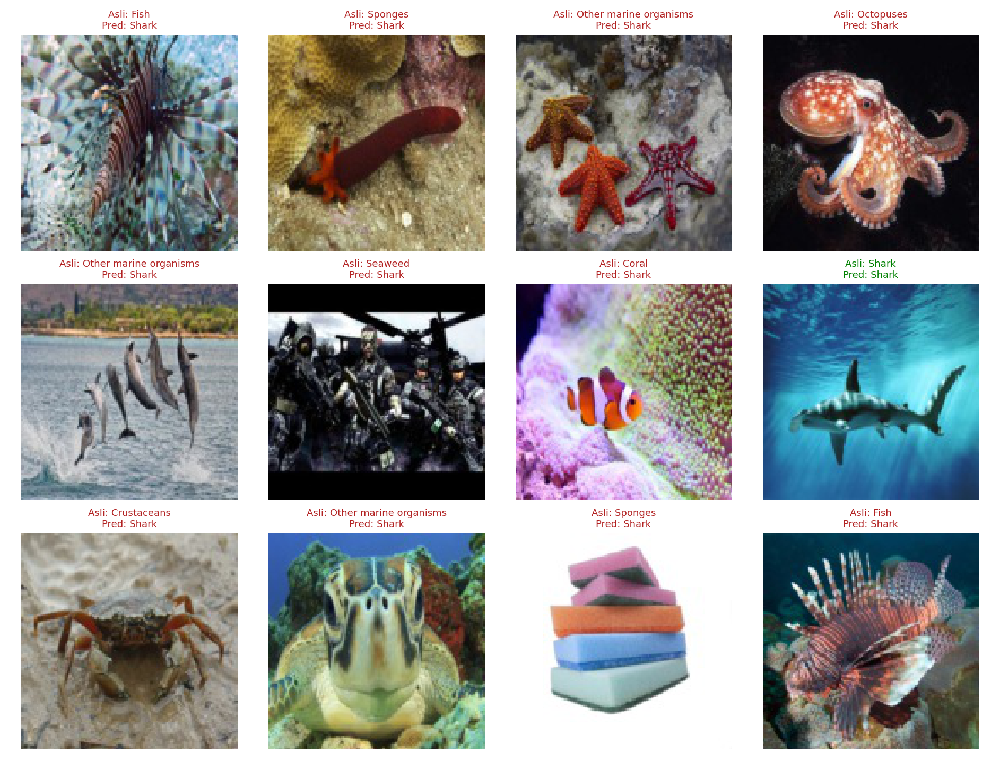


Visualisasi: gradcam_sampel.png


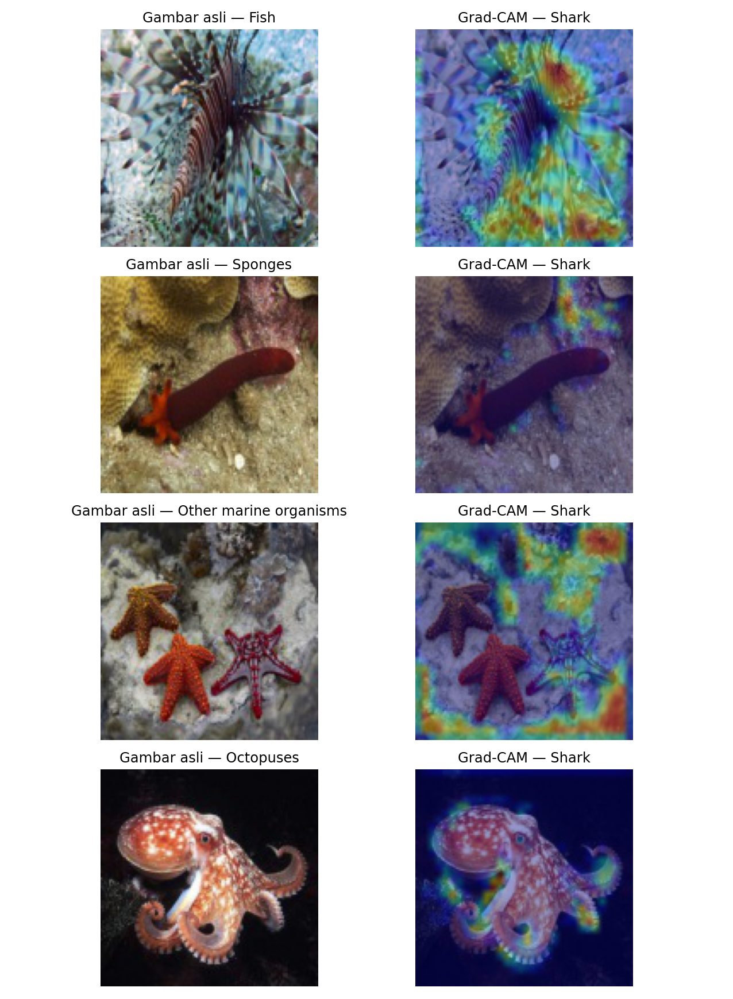

Analisis confusion matrix: Kesalahan paling banyak: Fish diprediksi sebagai Shark sebanyak 33 gambar.
Val-loss terendah terjadi pada epoch: 2


In [15]:
plot_history(h,OUT_DIR)
cm=confusion_matrix(y_true,y_pred,labels=list(range(len(classes))))
save_matrix(cm,classes,OUT_DIR)
examples=frames['test'][['path_asli','path_cache','kelas']].copy()
examples['prediksi']=[classes[i] for i in y_pred]
examples['confidence']=np.max(probs,axis=1)
examples['benar']=examples['kelas']==examples['prediksi']
examples.to_csv(OUT_DIR/'prediksi_data_test.csv',index=False)
try:
    samples_visualization(frames['test'],classes,y_true,y_pred,model,IMG_SIZE,OUT_DIR)
except Exception as ex:
    print('Prediksi dan Grad-CAM tidak dapat digambar di lingkungan ini:',ex)
for name in ['akurasi_loss.png','confusion_matrix.png','prediksi_sampel_test.png','gradcam_sampel.png']:
    if (OUT_DIR/name).exists():
        print('\nVisualisasi:',name)
        display(IPyImage(filename=str(OUT_DIR/name), width=800))
errors=cm.copy()
np.fill_diagonal(errors,0)
if errors.max()>0:
    i,j=np.unravel_index(errors.argmax(),errors.shape)
    print('Analisis confusion matrix: Kesalahan paling banyak:',classes[i],
          'diprediksi sebagai',classes[j],'sebanyak',int(errors[i,j]),'gambar.')
else:
    print('Analisis confusion matrix: Tidak ada kesalahan pada data test yang diuji.')
best=int(h['val_loss'].idxmin())+1
print('Val-loss terendah terjadi pada epoch:',best)

## Langkah 7 — Dashboard Streamlit
Dashboard `app.py` memuat ringkasan data, distribusi, contoh gambar dan analisisnya, grafik training, confusion matrix, tabel metrik per kelas, prediksi foto baru, skor Softmax, serta Grad-CAM gambar unggahan.

Jalankan di **terminal VS Code** pada folder proyek (bukan di sel notebook):
```bash
python -m streamlit run app.py
```
Kemudian ambil screenshot empat tab dashboard untuk laporan.

In [16]:
print('Dashboard siap dijalankan di terminal: python -m streamlit run app.py')
print('File model tersedia:',(OUT_DIR/'model_oceanic_cnn.keras').exists())

Dashboard siap dijalankan di terminal: python -m streamlit run app.py
File model tersedia: True


## Langkah 8 — Laporan praktikum
Simpan ringkasan dataset, metrik, grafik, dan draf laporan (`output/LAPORAN_HASIL_OTOMATIS.md`). Tambahkan screenshot dashboard secara manual. Angka akurasi dan analisis per kelas akan menggunakan **hasil yang benar-benar dihitung**.

In [17]:
count_map={k:int(v) for k,v in df['kelas'].value_counts().sort_index().items()}
summary={
  'dataset_url':SOURCE_URL,'jumlah_gambar':int(len(df)),'jumlah_kelas':len(classes),
  'kelas':classes,'kelas_dan_jumlah':count_map,
  'jumlah_train':len(frames['train']),'jumlah_validation':len(frames['validation']),
  'jumlah_test':len(frames['test']),'jumlah_dilewati_atau_duplikat':len(gambar_dilewati),
  'ukuran_gambar_cnn':IMG_SIZE,'batch_size':BATCH_SIZE,'learning_rate':LEARNING_RATE,
  'maks_epoch':EPOCHS,'normalisasi':'Rescaling(1/255) di dalam model',
  'rasio_kelas_terbesar_terkecil':float(max(count_map.values())/min(count_map.values())),
  'jumlah_mode_warna_asli':{str(k):int(v) for k,v in df['mode_asli'].value_counts().items()},
}
(OUT_DIR/'dataset_summary.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False),encoding='utf-8')
generate_report(summary,metrics,OUT_DIR)
print('Laporan otomatis:',OUT_DIR/'LAPORAN_HASIL_OTOMATIS.md')
print('Grafik, tabel, model dan metadata:',OUT_DIR)
print('TERAKHIR: Jalankan Streamlit dan masukkan screenshot ke laporan.')

Laporan otomatis: /Users/mochammadmarillivio/Downloads/Oceanic_Life_CNN_PERBAIKAN_FOLDER/output/LAPORAN_HASIL_OTOMATIS.md
Grafik, tabel, model dan metadata: /Users/mochammadmarillivio/Downloads/Oceanic_Life_CNN_PERBAIKAN_FOLDER/output
TERAKHIR: Jalankan Streamlit dan masukkan screenshot ke laporan.


### Checklist tugas
- [x] Notebook pengambilan dataset dan struktur folder per kelas (file 01)
- [x] EDA: distribusi, contoh, ukuran, warna, kualitas, ketimpangan
- [x] Resize, normalisasi, pembagian 80/10/10, augmentasi, label numerik
- [x] CNN, ReLU, Softmax, Adam, learning rate, 15 epoch, model tersimpan
- [x] Accuracy, Precision, Recall, F1-Score, tabel per kelas
- [x] Confusion matrix, kurva accuracy/loss, Grad-CAM, prediksi test
- [x] Dashboard Streamlit dan upload gambar baru
- [x] Draf laporan otomatis; **screenshot dashboard wajib ditambahkan setelah dijalankan**

Tanda centang menunjukkan **fitur kode tersedia**, bukan bahwa training dataset asli sudah dijalankan.